In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("adult.csv")

print(df.head())
print("Shape:", df.shape)

   age workclass  fnlwgt     education  education.num marital.status  \
0   90         ?   77053       HS-grad              9        Widowed   
1   82   Private  132870       HS-grad              9        Widowed   
2   66         ?  186061  Some-college             10        Widowed   
3   54   Private  140359       7th-8th              4       Divorced   
4   41   Private  264663  Some-college             10      Separated   

          occupation   relationship   race     sex  capital.gain  \
0                  ?  Not-in-family  White  Female             0   
1    Exec-managerial  Not-in-family  White  Female             0   
2                  ?      Unmarried  Black  Female             0   
3  Machine-op-inspct      Unmarried  White  Female             0   
4     Prof-specialty      Own-child  White  Female             0   

   capital.loss  hours.per.week native.country income  
0          4356              40  United-States  <=50K  
1          4356              18  United-States

In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nIncome distribution:")
print(df["income"].value_counts())

Missing values:
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

Duplicate rows: 24

Income distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64


In [4]:
df = df.drop_duplicates()

df = df.replace(r"^\s*\?\s*$", pd.NA, regex=True)
df = df.dropna()

df["income"] = df["income"].str.strip()

print("Shape after cleaning:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Shape after cleaning: (30139, 15)
Missing values: 0


In [5]:
df["income"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

print(df["income"].value_counts())

income
0    22633
1     7506
Name: count, dtype: int64


In [6]:
X = df.drop("income", axis=1)
y = df["income"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (30139, 14)
Target shape: (30139,)


In [7]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print(X.head())
print("Final features shape:", X.shape)

   age  fnlwgt  education.num  capital.gain  capital.loss  hours.per.week  \
1   82  132870              9             0          4356              18   
3   54  140359              4             0          3900              40   
4   41  264663             10             0          3900              40   
5   34  216864              9             0          3770              45   
6   38  150601              6             0          3770              40   

   workclass_Local-gov  workclass_Private  workclass_Self-emp-inc  \
1                    0                  1                       0   
3                    0                  1                       0   
4                    0                  1                       0   
5                    0                  1                       0   
6                    0                  1                       0   

   workclass_Self-emp-not-inc  ...  native.country_Portugal  \
1                           0  ...                        0

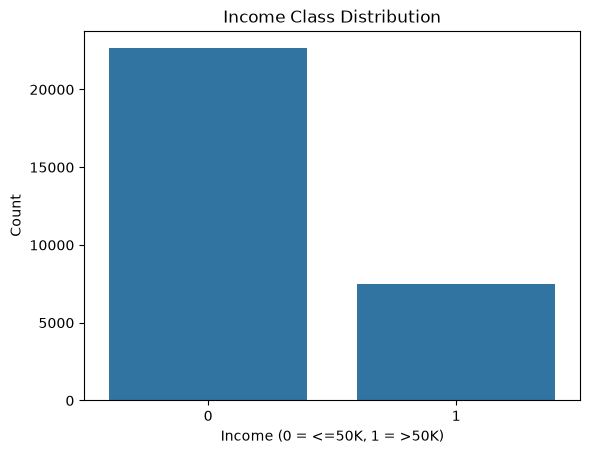

In [8]:
sns.countplot(data=df, x="income")

plt.title("Income Class Distribution")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Count")
plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24111, 96)
Testing data: (6028, 96)


In [10]:
model = GaussianNB()

model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [11]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head(10).tolist())

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
[0, 0, 1, 0, 0, 0, 0, 1, 1, 0]

Predicted values:
[0 0 0 0 0 0 0 1 1 0]


In [12]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred, zero_division=0
))

Accuracy: 0.7909754479097545
Precision: 0.6680613668061367
Recall: 0.31912058627581613
F1-score: 0.43192064923354373


In [13]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["<=50K", ">50K"],
    zero_division=0
))

              precision    recall  f1-score   support

       <=50K       0.81      0.95      0.87      4527
        >50K       0.67      0.32      0.43      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.63      0.65      6028
weighted avg       0.77      0.79      0.76      6028



[[4289  238]
 [1022  479]]


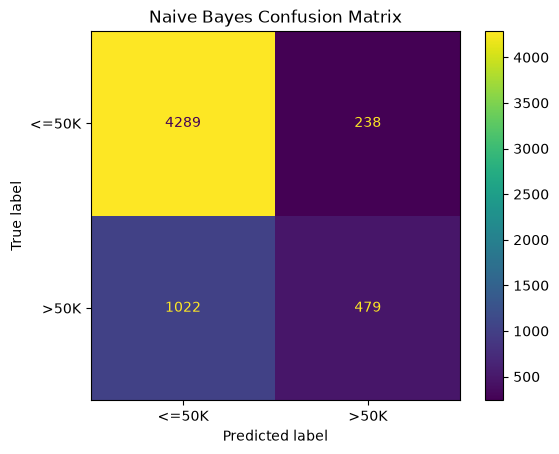

In [14]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
).plot()

plt.title("Naive Bayes Confusion Matrix")
plt.show()